In [ ]:
%load_ext autoreload
%autoreload 2
from hypnose_behavior.visualization.choice import plot_choice_history
from hypnose_behavior.visualization.rewards import (
    plot_cumulative_rewards,
    plot_cumulative_rewards_by_trial,
)
from hypnose_behavior.io.save import use_style
from hypnose_behavior.modelling.discrimination_learning.data import load_discrimination_data
from hypnose_behavior.modelling.discrimination_learning.diagnostics import choice_persistence, lose_shift_summary
from hypnose_behavior.modelling.discrimination_learning.log_regression import (
    fit_session_models,
    gain_decomposition,
    model_comparison,
    overnight_share,
    shared_slope,
)
from hypnose_behavior.modelling.discrimination_learning.session_gain import edge_gains, gain_summary
from hypnose_behavior.modelling.discrimination_learning.sigmoid import (
    VARIANTS,
    fit_accuracy,
    fit_rate,
    pick_variant,
    sigmoid_anchors,
    sigmoid_optima,
    variant_test,
)
from hypnose_behavior.visualization.modelling.discrimination_learning.log_regression import (
    plot_gain_decomposition,
)
from hypnose_behavior.visualization.modelling.discrimination_learning.cumulative import (
    plot_cohort_accuracy,
    plot_cohort_accuracy_normalized,
    plot_cumulative_panels,
    plot_excess_by_index,
)

from hypnose_behavior.visualization.modelling.discrimination_learning.sigmoid import (
    plot_accuracy_sigmoid,
    plot_sigmoid_anchors,
)
from hypnose_behavior.modelling.discrimination_learning.step import (
    fit_step,
    step_modes,
    step_summary,
    step_test,
)
from hypnose_behavior.visualization.modelling.discrimination_learning.step import plot_step_posterior
from hypnose_behavior.visualization.modelling.discrimination_learning.session_gain import (
    plot_edge_gains,
    plot_position_profile,
    plot_session_profiles,
)
from hypnose_behavior.visualization.modelling.discrimination_learning.diagnostics import (
    plot_failed_attempt_accuracy,
    plot_initiation_rate,
    plot_lose_shift,
)
from hypnose_behavior.modelling.discrimination_learning.state_space import (
    SIGMA_SCALE,
    SIGMA_SCALES,
    fit_state_space,
    gate_table,
    state_space_changes,
    state_space_summary,
)
from hypnose_behavior.visualization.modelling.discrimination_learning.state_space import plot_state_space
import pandas as pd

%matplotlib widget

use_style("presentation")

# Visualize a sessions choice history

In [ ]:
# Plots all choices for one or more sessions
choice_plots = plot_choice_history(
    subjid=45, 
    dates=[20260107], 
    fa_types=["FA_time_in", "FA_time_out"],
    save=False, 
    show_legend=True,
    title=False,
    lw_scale=3,
    xlim=(0,8500),
    marker_scale=3,)

# Subjids

Define sets of subjids to be used in downstream plots (e.g., cohorts with their dates). 

In [2]:
# Odour-discrimination cohorts. load_discrimination_data keeps each session's odour-discrimination runs
# (protocol_mode per run), whatever the selection.
# A/B: from stage 2 on.
ab_cohort = {60: {"ses_range": (2, 16)},
             61: {"ses_range": (2, 16)},
             62: {"ses_range": (2, 16)},
             63: {"ses_range": (2, 10)},
             #64: {"ses_range": (2, 14)},
             65: {"ses_range": (2, 11)},
             66: {"ses_range": (2, 10)}}
# G/E: 63 and 66 from 2026-09-29 (63 ses 50 is hidden rule and drops out).
ge_cohort = {63: {"date_range": (20260929, 20261012)},
             66: {"date_range": (20260929, 20261012)}}

ab = load_discrimination_data(ab_cohort)
ge = load_discrimination_data(ge_cohort)
ab["sessions"]

[load_discrimination_data] sub-63 ses-50: no odour-discrimination trial or attempt, skipped


,subjid,ses,date,session_idx,n_runs,n_trials,n_attempts
0,60,2,20260709,0,1,49,31
1,60,3,20260710,1,1,130,116
2,60,4,20260713,2,1,110,55
3,60,5,20260714,3,1,132,81
4,60,6,20260715,4,1,102,73
...,...,...,...,...,...,...,...
67,66,6,20260727,4,1,180,388
68,66,7,20260728,5,1,185,206
69,66,8,20260729,6,1,129,59
70,66,9,20260730,7,1,139,63


# Cumulative rewards over time (1) or trial id (2)

In [ ]:
# Plot cumulative rewards for multiple sessions and subjects. Can be split by days or consecutive. Can use dictionary to define specific dates for each subject. 
plot_cumulative_rewards(subjids=ge_cohort, dates=None, split_days=False, save=True, show_gap_shading=False, show_session_boundaries=False, show_title=False, show_legend=True)

In [ ]:
# Cumulative rewards vs CONTINUOUS TRIAL INDEX (global_trial_id, concatenated across sessions):

plot_cumulative_rewards_by_trial(subjids=subjids, dates=None, save=False)

# Accuracy over task time

Share correct over each 50 consecutive choices, at each choice's task time (the
odour-discrimination runs laid end to end), one colour per animal. `mode` is
`"completed"`, `"attempts"` or `"both"` (completed solid, attempts dashed); session
boundaries are drawn for a single animal.

In [ ]:
fig_accuracy = plot_cohort_accuracy(data=ge, save=True, window=200, mode="completed")
# One animal, both modes, with its session boundaries (loads that animal):
# plot_cohort_accuracy({62: ab_cohort[62]}, mode="both")
# modes: completed, attempts, both

In [ ]:
# Each animal from its first reward (0) to its last (1), 150-choice window.
# modes: completed, attempts, both
fig_accuracy_normalized = plot_cohort_accuracy_normalized(data=ab, save=True, window=150,
                                                          mode="completed", show_mean=True)


# Diagnostics: is completed-trials-only defensible?

Loads trials and failed initiation attempts once; every plot below reuses `ab`.

In [ ]:
ab = load_discrimination_data(ab_cohort)
ab["sessions"]

## D1: initiation rate

Initiated trials / (trials + failed attempts with a poke), per session.

In [ ]:
figs_d1 = plot_initiation_rate(data=ab, save=True, legend=False)

## D2: accuracy after failed attempts

Port choice after a failed attempt, scored against that attempt's odor, next to completed-trial accuracy. Zero-poke attempts (poke ended before the valve opened) are shown separately.

In [ ]:
figs_d2 = plot_failed_attempt_accuracy(data=ab, save=True, legend=False, show=[1,2])

## D3: lose-shift

Completed trials split by the failed attempt right before them. Elimination would show as `wrong port` above `none`.

In [ ]:
figs_d3 = plot_lose_shift(data=ab, save=True)
lose_shift_summary(ab, by=())

## D4: choice persistence across attempts

For trials with ≥2 (a.) or ≥ 1 (b.) port-visiting failed attempts: agreement between consecutive attempts, and between the last attempt and the trial's choice, against the chance agreement their accuracy implies (p₁p₂ + (1−p₁)(1−p₂), with p per animal, session and odor).

In [ ]:
d4 = choice_persistence(ab)
display(d4["distribution"])
d4["summary"]

# 0.6 Logistic regression: within-session vs overnight

Three nested models per animal, on the completed-trial rows:

| | form | says |
|---|---|---|
| `M_a` | `logit p = a_s` | every gain falls between sessions |
| `M_b` | `logit p = a_s + b·x` | one within-session slope, shared by sessions |
| `M_c` | `logit p = a_s + b_s·x` | a within-session slope per session |

`x` is a trial's position in its session, 0 at the first and 1 at the last.
**The hypothesis test is `M_a vs M_c`** — `M_b` averages an early positive slope against
a late negative one and can come back flat while both are real.

In [ ]:
# Sessions under `min_trials` are dropped whole: too few trials to identify a
# within-session slope, and a short session that is all-correct separates the fit.
fits = fit_session_models(ab, mode="completed")
pd.concat(f["sessions"] for f in fits.values()).query("not kept")

In [ ]:
model_comparison(fits)

In [ ]:
# M_b's single slope per animal: the descriptive average, not the test.
shared_slope(fits)

## Decomposition

From `M_c`, the change in log-odds splits exactly into a within-session and an overnight
part, `W_s = b_s` and `O_s = a_{s+1} − a_s − b_s`, which telescope to the total.
Each is a contrast of `M_c`, so each carries an exact standard error.

`overnight_share` is `sum(O) / total`. It only reads as a percentage while the two
components point the same way — `mixed_signs` marks the animals where they do not, and
there `within_total` and `overnight_total` in log-odds are what to report. `total_z` says
whether the total change is itself distinguishable from zero; where it is not, the share
is undefined.

In [ ]:
overnight_share(fits)

In [ ]:
# `gap_days` is the calendar distance across a boundary (a weekend makes it 3). A boundary
# with a dropped session inside it is `across_gap`, kept out of sum(O).
gain_decomposition(fits)

In [ ]:
figs_0_6 = plot_gain_decomposition(fits=fits, save=True)

## Robustness: every choice attempt

The same models over the attempt-level rows (plan 0.8) — completed trials plus failed
attempts that ended in a port visit. `x` is renormalized over that axis, so the two modes
never mix.

In [ ]:
fits_attempts = fit_session_models(ab, mode="attempts")
model_comparison(fits_attempts)

In [ ]:
overnight_share(fits_attempts)

In [ ]:
figs_0_6_attempts = plot_gain_decomposition(fits=fits_attempts, save=False)

# 0.7 Within- and across-session gain

Raw accuracy over the first and last N = 20 trials of each session, on the rows `fits`
was fitted on. **within** is last N minus first N of a session; **across** is the next
session's first N minus this one's last N. One window's accuracy has an SE near 0.1, so
read the means over sessions, not single gains.

In [ ]:
figs_0_7 = plot_edge_gains(fits=fits, save=True)
gains = edge_gains(fits)
display(gain_summary(gains))
gain_summary(gains, by=())

## Accuracy by position in the session

Pooled over each animal's sessions, by trial number (top) and by fraction of the
session (bottom). `M_a fit` is what the mix of sessions alone produces (only long
sessions reach late trial numbers); `M_c fit` is what the per-session slopes add up
to once pooled. A flat pooled profile that `M_c` also reproduces means the slopes
cancel across sessions, which the per-session panels below show one at a time.

In [ ]:
figs_0_7_profile = plot_position_profile(fits=fits, save=True)

In [ ]:
# Each session's binned accuracy against its own M_c line; W is M_c's gain in log-odds.
figs_0_7_sessions = plot_session_profiles(fits=fits, save=True)

## Robustness: every choice attempt

The same windows counted in choice attempts, on the rows of `fits_attempts`.

In [ ]:
gain_summary(edge_gains(fits_attempts), by=())

# 1.1 Initiations, excess correct, rewards

One figure per animal on task time: the odour-discrimination runs laid end to end,
so nights and gaps between runs take no width. Dotted verticals are session
boundaries. Each line is scaled to its own maximum, so they compare by shape; the
legend gives the raw final counts.

- **initiations** (blue): engagement.
- **excess correct** (orange), `cumsum(y − 0.5)`: flat is chance. A rise the blue line
  does not share is a change in accuracy; orange steeper than blue means accuracy above
  the animal's average. **Two bends in orange make the single-sigmoid fit of 2.1
  invalid.**
- **rewards** (faded aqua): the product of the two.

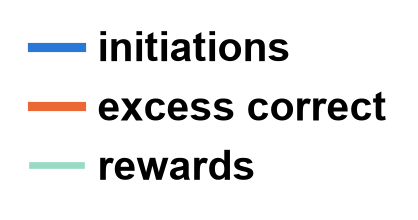

Final counts (completed):
 subjid  initiations  excess correct  rewards
     63          585            55.5      348
     66          758             296      675


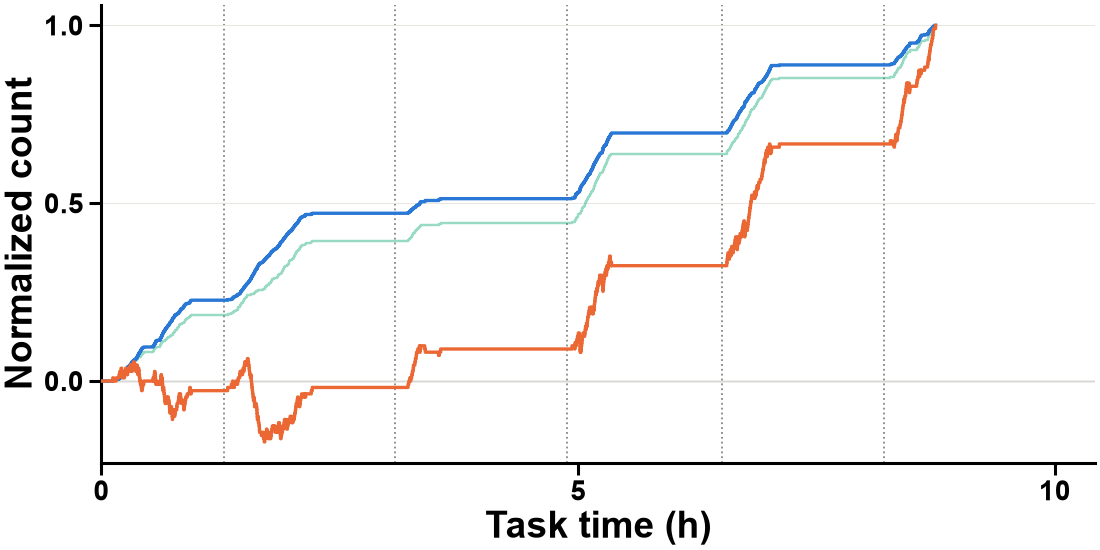

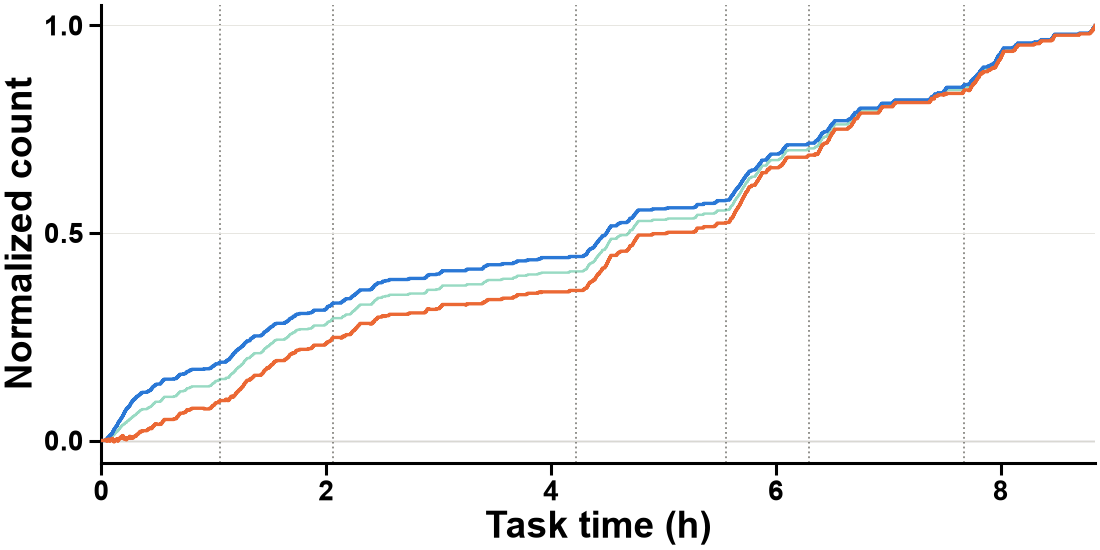

In [3]:
figs_1_1 = plot_cumulative_panels(data=ge, save=True, legend=False, show=[1,2,3])

In [ ]:
# Attempts mode: B over every choice attempt; A adds the failed attempts that ended
# in a port visit.
figs_1_1_attempts = plot_cumulative_panels(data=ab, mode="attempts", save=False)

## Excess correct by trial

The same `cumsum(y − 0.5)` against the number of choices so far instead of task time.
Every choice is one step, so the slope is accuracy − 0.5 and engagement is off the
axis: a bend here is a change in accuracy. A bend on task time that disappears here was
engagement; one that stays is knowledge.

In [ ]:
figs_excess_index = plot_excess_by_index(data=ge, save=True, legend=False)

In [ ]:
# Attempts mode: over every choice attempt.
figs_excess_index_attempts = plot_excess_by_index(data=ab, mode="attempts", save=True)

# 1.2 State-space model (Smith et al. 2004)

Accuracy trial by trial with a 95% credible band, no curve shape assumed: a random walk in
log-odds, `x_k = x_{k−1} + σ·z_k`, `y_k ~ Bernoulli(logistic(x_k))`, one animal at a time
(PyMC, NUTS, non-centered). The start `x_0 ~ N(0, 1.5)` is free, so an animal that begins
above chance shows no early rise.

- **learning trial**: the first trial from which P(x_k > 0) stays above 0.95 to the end.
- **changes**: counted on the session means of p_k, per draw. The median means are cut at
  reversals ≥ 0.10 and at plateaus (≥ 2 sessions within 0.04); a piece is a change when it
  moves ≥ 0.10 and ≥ 95% of draws agree on its direction. Set on synthetic data only; it
  errs towards more changes (a steep ramp can split in two).
- **gate**: one change → the 2.1–2.6 results stand; more → §2.7, and the sigmoid's `w` is
  not read as suddenness.

`boundary=True` gives the steps across session boundaries their own σ_b; `"shifted"` puts
σ_b half a session later as the control. §0.3 predicts `boundary_share` above `shifted_share`.


In [ ]:
walk = fit_state_space(ab)
walk_b = fit_state_space(ab, boundary=True)
walk_s = fit_state_space(ab, boundary="shifted")
display(state_space_summary(walk, walk_b, walk_s).round(3))
state_space_changes(walk).round(3)

In [ ]:
# Top: observed excess correct (orange) and the expected excess, median and 95% band.
# Middle: accuracy per 50 trials, p_k with its band, session means (thick bars).
# Bottom: P(x_k > 0) against 0.95. Dashed black: learning trial. ▲/▼: counted changes.
# Dotted grey: the boundary-σ fit.
figs_1_2 = plot_state_space(walk, boundary=walk_b, save=True)

In [ ]:
#σ-prior sensitivity
walk_prior = {s: walk if s == SIGMA_SCALE else fit_state_space(ab, sigma_scale=s)
              for s in SIGMA_SCALES}
state_space_summary(*walk_prior.values()).pivot(
    index="subjid", columns="sigma_scale", values=["n_changes", "learning_trial", "sigma"])

# 2.1–2.3 Single sigmoid

One erf sigmoid per animal on each choice's correctness over the trial index:

`p(k) = p_i + (p_f − p_i)/2 · [1 + erf((k − k_s)/w)]`

`w` is the suddenness: `k_s ± w` spans 84% of the change, 10%→90% takes `1.81·w`, and
`w < 1` is faster than the data resolve. `p_i` is free, or fixed at 0.5 (`chance`);
`pick_variant` keeps free only where a likelihood-ratio test rejects 0.5 (p < 0.05).

The likelihood is multimodal, so every **separated optimum** is kept: every peak of the
lnL surface over (`k_s`, `w`) that stands at least 2 lnL above the saddle toward a higher
one. Two separated optima of similar lnL mean two changes. Two changes in a row can also
come back as one wide ramp that beats either step, so a large `w` is its own warning.
`inside` is False when the best `k_s` lies outside the data: a ramp across the whole
sequence, not a change at a point.

In [ ]:
acc = {variant: fit_accuracy(ab, "completed", variant) for variant in VARIANTS}
sigmoid_optima(*acc.values()).round(3)

In [ ]:
# Initial accuracy free vs fixed at 0.5: likelihood-ratio test, df 1. Free is kept only
# where p < 0.05.
display(variant_test(acc).round(4))
acc_best = pick_variant(acc)

In [ ]:
# Orange: the observed choices. Blue: initial free. Dashed grey: initial 0.5.
# Top: observed excess correct and each fit's expected excess, cumsum(p(k) − 0.5).
# Middle: accuracy per 50 trials and each fit's p(k). Bottom: lnL over (k_s, w); the
# orange contour is the 95% region and the dots are the optima, numbered by rank.
figs_2_acc = plot_accuracy_sigmoid(fits=acc, save=True, legend=False, show_fit="best")

## Robustness: every choice attempt

The same fits over `choice_attempt_idx`. If `k_s` barely moves, dropping the failed
attempts from the primary mode is earned.

In [ ]:
acc_attempts = {variant: fit_accuracy(ab, "attempts", variant) for variant in VARIANTS}
sigmoid_optima(*acc_attempts.values()).round(3)

In [ ]:
figs_2_acc_attempts = plot_accuracy_sigmoid(fits=acc_attempts, save=True)

## Engagement, rewards and accuracy on one clock

The same curve as a rate: an inhomogeneous Poisson process on initiation times
(engagement) and on reward times over task hours. Rewards are initiation rate × accuracy,
so their midpoint only says which of the two drove the reward rate. The accuracy `k_s` is
read onto task time through that trial's timestamp.

Events come in bouts and the rate changes from session to session, so the rate fits are
overdispersed: their lnL differences and width intervals are far too sharp, and a
session-to-session change fits as a step at a boundary. Read them for *where*, not *how
sudden*.

In [ ]:
engagement = fit_rate(ab)
reward_rate = fit_rate(ab, "rewards")
sigmoid_anchors(acc_best, engagement, reward_rate).round(3)

In [ ]:
# Top: the 1.1 counts (solid) with each fit's expected running count (dashed): the rate
# fits integrated over task time, the accuracy fit as cumsum(p(k) − 0.5) at each trial's
# time; dots mark the midpoints. Middle: initiations and rewards per hour, per session
# (bars), with the rate sigmoids. Bottom: accuracy per session (bars) with the accuracy
# sigmoid at each trial's time. Dashed verticals: each fit's midpoint.
figs_2_anchors = plot_sigmoid_anchors(data=ab, accuracy=acc_best,
                                      engagement=engagement, rewards=reward_rate,
                                      save=True)


# 2.4–2.6 Step model

The sigmoid with w → 0: accuracy jumps once, at trial k_s. `step_test` asks whether the
sigmoid fits better than a step at all: `ΔlnL` is the best sigmoid's lead over the best
step, and `step` is True where ΔlnL < 1.92 (p = 0.05, one parameter). Only there is the
step a description of the change; for a gradual change the posterior is drawn but is not
a result.

The posterior over k_s integrates both accuracies out under Beta(1, 1) (the initial held
at 0.5 for a chance fit), excluding the first and last 20 trials. Peaks within one
session are one switch; a posterior with modes in different sessions (each ≥ 5% of the
mass) is flagged multimodal and not summarized as mean ± SD. `ΔlnL_*_const` is each
model's lead over no change at all.

In [ ]:
step_test(acc_best).round(3)

In [ ]:
steps = fit_step(acc_best)
display(step_summary(steps).round(3))
step_modes(steps).round(3)

In [ ]:
# Top: observed excess correct, the step at the posterior's peak, the sigmoid.
# Middle: P(k_s) over the whole sequence. Bottom: the same, zoomed, modes labelled.
figs_2_step = plot_step_posterior(steps, save=True)

## Gate for Sigmoid fit

In [ ]:
gate_table(walk, steps, walk_b, walk_s).round(3)

## Robustness: every choice attempt

In [ ]:
acc_attempts_best = pick_variant(acc_attempts)
steps_attempts = fit_step(acc_attempts_best)
display(step_test(acc_attempts_best).round(3))
step_summary(steps_attempts).round(3)

In [ ]:
figs_2_step_attempts = plot_step_posterior(steps_attempts, save=True)